In [ ]:


import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshigoyal7/credit-card-customers")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'credit-card-customers' dataset.
Path to dataset files: /kaggle/input/credit-card-customers


In [ ]:
import numpy as np
import pandas as pd
import os
import sklearn
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv(path+"/BankChurners.csv")
data.describe()


,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990


In [ ]:
data.isna().sum()
for col in data.columns:
    pct = (data[col] == 'Unknown').sum()
    print(f"Unknown in {col}: {pct} ")

Unknown in CLIENTNUM: 0 
Unknown in Attrition_Flag: 0 
Unknown in Customer_Age: 0 
Unknown in Gender: 0 
Unknown in Dependent_count: 0 
Unknown in Education_Level: 1519 
Unknown in Marital_Status: 749 
Unknown in Income_Category: 1112 
Unknown in Card_Category: 0 
Unknown in Months_on_book: 0 
Unknown in Total_Relationship_Count: 0 
Unknown in Months_Inactive_12_mon: 0 
Unknown in Contacts_Count_12_mon: 0 
Unknown in Credit_Limit: 0 
Unknown in Total_Revolving_Bal: 0 
Unknown in Avg_Open_To_Buy: 0 
Unknown in Total_Amt_Chng_Q4_Q1: 0 
Unknown in Total_Trans_Amt: 0 
Unknown in Total_Trans_Ct: 0 
Unknown in Total_Ct_Chng_Q4_Q1: 0 
Unknown in Avg_Utilization_Ratio: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2: 0 


In [ ]:
data = data.drop(columns=['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1'])
data = data.drop(columns=['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'])

In [ ]:
data

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,...,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,...,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,...,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,...,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000


In [ ]:
income_order = [
    'Less than $40K',
    '$40K - $60K',
    '$60K - $80K',
    '$80K - $120K',
    '$120K +'
]
data['Income_Category'] = pd.Categorical(
    data['Income_Category'],
    categories=income_order,
    ordered=True
)
data['Income_Category'] = data['Income_Category'].cat.codes

In [ ]:
data

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,2,Blue,39,...,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,0,Blue,44,...,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,3,Blue,36,...,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,0,Blue,34,...,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,2,Blue,21,...,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,772366833,Existing Customer,50,M,2,Graduate,Single,1,Blue,40,...,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,1,Blue,25,...,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,716506083,Attrited Customer,44,F,1,High School,Married,0,Blue,36,...,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,1,Blue,36,...,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000


In [ ]:
data['Income_Category'].unique()

array([ 2,  0,  3,  1,  4, -1], dtype=int8)

In [ ]:
data['Card_Category'].unique()
data['Education_Level'].unique()

array(['High School', 'Graduate', 'Uneducated', 'Unknown', 'College',
       'Post-Graduate', 'Doctorate'], dtype=object)

In [ ]:
flag = {
    'Existing Customer': 0,
    'Attrited Customer': 1
}
data['Attrition_Flag'] = data['Attrition_Flag'].map(flag)

In [ ]:
gender = {
    'M': 0,
    'F': 1
}
data['Gender'] = data['Gender'].map(gender)
education_level = ['Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate']
data['Education_Level'] = pd.Categorical(
    data['Education_Level'],
    categories=education_level,
    ordered=True
)
data['Education_Level'] = data['Education_Level'].cat.codes
data['Education_Level'] = data['Education_Level'].replace(-1, np.nan)
data['Income_Category'] = data['Income_Category'].replace(-1, np.nan)
data['Marital_Status'] = data['Marital_Status'].replace('Unknown', np.nan)

for col in ['Education_Level', 'Marital_Status', 'Income_Category']:
    pct = data[col].isna().sum() / len(data) * 100
    print(f"{col}: {pct:.2f}% missing")

data['Education_Unknown'] = data['Education_Level'].isna().astype(int)
data['Income_Unknown'] = data['Income_Category'].isna().astype(int)
data['Marital_Unknown'] = data['Marital_Status'].isna().astype(int)

mode_val_marital = data['Marital_Status'].mode()[0]

data['Marital_Status'] = data['Marital_Status'].fillna(mode_val_marital)
data['Education_Level'] = data['Education_Level'].fillna(data['Education_Level'].median())
data['Income_Category'] = data['Income_Category'].fillna(data['Income_Category'].median())

data = pd.get_dummies(data, columns=['Card_Category'], prefix='Card_Category')
data = pd.get_dummies(data, columns=['Marital_Status'], prefix='Marital')

data = data.drop(columns=['CLIENTNUM'])
data

Education_Level: 15.00% missing
Marital_Status: 7.40% missing
Income_Category: 10.98% missing


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Education_Unknown,Income_Unknown,Marital_Unknown,Card_Category_Blue,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Marital_Divorced,Marital_Married,Marital_Single
0,0,45,0,3,1.0,2.0,39,5,1,3,...,0,0,0,True,False,False,False,False,True,False
1,0,49,1,5,3.0,0.0,44,6,1,2,...,0,0,0,True,False,False,False,False,False,True
2,0,51,0,3,3.0,3.0,36,4,1,0,...,0,0,0,True,False,False,False,False,True,False
3,0,40,1,4,1.0,0.0,34,3,4,1,...,0,0,1,True,False,False,False,False,True,False
4,0,40,0,3,0.0,2.0,21,5,1,0,...,0,0,0,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,0,50,0,2,3.0,1.0,40,3,2,3,...,0,0,0,True,False,False,False,False,False,True
10123,1,41,0,2,2.0,1.0,25,4,2,3,...,1,0,0,True,False,False,False,True,False,False
10124,1,44,1,1,1.0,0.0,36,5,3,4,...,0,0,0,True,False,False,False,False,True,False
10125,1,30,0,2,3.0,1.0,36,4,3,3,...,0,0,1,True,False,False,False,False,True,False


In [ ]:
data.isna().sum()

,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Income_Category,0
Months_on_book,0
Total_Relationship_Count,0
Months_Inactive_12_mon,0
Contacts_Count_12_mon,0


In [ ]:
data

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Education_Unknown,Income_Unknown,Marital_Unknown,Card_Category_Blue,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Marital_Divorced,Marital_Married,Marital_Single
0,0,45,0,3,1.0,2.0,39,5,1,3,...,0,0,0,True,False,False,False,False,True,False
1,0,49,1,5,3.0,0.0,44,6,1,2,...,0,0,0,True,False,False,False,False,False,True
2,0,51,0,3,3.0,3.0,36,4,1,0,...,0,0,0,True,False,False,False,False,True,False
3,0,40,1,4,1.0,0.0,34,3,4,1,...,0,0,1,True,False,False,False,False,True,False
4,0,40,0,3,0.0,2.0,21,5,1,0,...,0,0,0,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,0,50,0,2,3.0,1.0,40,3,2,3,...,0,0,0,True,False,False,False,False,False,True
10123,1,41,0,2,2.0,1.0,25,4,2,3,...,1,0,0,True,False,False,False,True,False,False
10124,1,44,1,1,1.0,0.0,36,5,3,4,...,0,0,0,True,False,False,False,False,True,False
10125,1,30,0,2,3.0,1.0,36,4,3,3,...,0,0,1,True,False,False,False,False,True,False


In [ ]:
data.describe()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Education_Unknown,Income_Unknown,Marital_Unknown
count,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,...,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,0.160660,46.325960,0.529081,2.346203,2.051940,1.305322,35.928409,3.812580,2.341167,2.455317,...,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.149995,0.109805,0.073961
std,0.367235,8.016814,0.499178,1.298908,1.302722,1.284294,7.986416,1.554408,1.010622,1.106225,...,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.357084,0.312663,0.261720
min,0.000000,26.000000,0.000000,0.000000,0.000000,0.000000,13.000000,1.000000,0.000000,0.000000,...,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,41.000000,0.000000,1.000000,1.000000,0.000000,31.000000,3.000000,2.000000,2.000000,...,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000000,0.000000,0.000000
50%,0.000000,46.000000,1.000000,2.000000,2.000000,1.000000,36.000000,4.000000,2.000000,2.000000,...,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000000,0.000000,0.000000
75%,0.000000,52.000000,1.000000,3.000000,3.000000,2.000000,40.000000,5.000000,3.000000,3.000000,...,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000000,0.000000,0.000000
max,1.000000,73.000000,1.000000,5.000000,5.000000,4.000000,56.000000,6.000000,6.000000,6.000000,...,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,1.000000,1.000000,1.000000


In [ ]:
existing = data[data['Attrition_Flag'] == 0]
attrited = data[data['Attrition_Flag'] == 1]

In [ ]:
existing.describe()


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Education_Unknown,Income_Unknown,Marital_Unknown
count,8500.0,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,...,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,0.0,46.262118,0.520941,2.335412,2.041176,1.312118,35.880588,3.914588,2.273765,2.356353,...,1256.604118,7470.273400,0.772510,4654.655882,68.672588,0.742434,0.296412,0.148588,0.108824,0.072941
std,0.0,8.081157,0.499591,1.303229,1.294116,1.279549,8.021810,1.528949,1.016741,1.081436,...,757.745354,9087.671862,0.217783,3512.772635,22.919011,0.228054,0.272568,0.355703,0.311436,0.260055
min,0.0,26.000000,0.000000,0.000000,0.000000,0.000000,13.000000,1.000000,0.000000,0.000000,...,0.000000,15.000000,0.256000,816.000000,11.000000,0.028000,0.000000,0.000000,0.000000,0.000000
25%,0.0,41.000000,0.000000,1.000000,1.000000,0.000000,31.000000,3.000000,1.000000,2.000000,...,800.000000,1184.500000,0.643000,2384.750000,54.000000,0.617000,0.055000,0.000000,0.000000,0.000000
50%,0.0,46.000000,1.000000,2.000000,2.000000,1.000000,36.000000,4.000000,2.000000,2.000000,...,1364.000000,3469.500000,0.743000,4100.000000,71.000000,0.721000,0.211000,0.000000,0.000000,0.000000
75%,0.0,52.000000,1.000000,3.000000,3.000000,2.000000,40.000000,5.000000,3.000000,3.000000,...,1807.000000,9978.250000,0.860000,4781.250000,82.000000,0.833000,0.529250,0.000000,0.000000,0.000000
max,0.0,73.000000,1.000000,5.000000,5.000000,4.000000,56.000000,6.000000,6.000000,5.000000,...,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.994000,1.000000,1.000000,1.000000


In [ ]:
attrited.describe()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Education_Unknown,Income_Unknown,Marital_Unknown
count,1627.0,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,...,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000
mean,1.0,46.659496,0.571604,2.402581,2.108175,1.269822,36.178242,3.279656,2.693301,2.972342,...,672.822987,7463.216472,0.694277,3095.025814,44.933620,0.554386,0.162475,0.157345,0.114935,0.079287
std,0.0,7.665652,0.494998,1.275010,1.345797,1.308631,7.796548,1.577782,0.899623,1.090537,...,921.385582,9109.208129,0.214924,2308.227629,14.568429,0.226854,0.264458,0.364238,0.319042,0.270269
min,1.0,26.000000,0.000000,0.000000,0.000000,0.000000,13.000000,1.000000,0.000000,0.000000,...,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.0,41.000000,0.000000,2.000000,1.000000,0.000000,32.000000,2.000000,2.000000,2.000000,...,0.000000,1587.000000,0.544500,1903.500000,37.000000,0.400000,0.000000,0.000000,0.000000,0.000000
50%,1.0,47.000000,1.000000,2.000000,2.000000,1.000000,36.000000,3.000000,3.000000,3.000000,...,0.000000,3488.000000,0.701000,2329.000000,43.000000,0.531000,0.000000,0.000000,0.000000,0.000000
75%,1.0,52.000000,1.000000,3.000000,3.000000,2.000000,40.000000,5.000000,3.000000,4.000000,...,1303.500000,9257.500000,0.856000,2772.000000,51.000000,0.692000,0.231000,0.000000,0.000000,0.000000
max,1.0,68.000000,1.000000,5.000000,5.000000,4.000000,56.000000,6.000000,6.000000,6.000000,...,2517.000000,34516.000000,1.492000,10583.000000,94.000000,2.500000,0.999000,1.000000,1.000000,1.000000


In [ ]:
data.isna().sum()

,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Income_Category,0
Months_on_book,0
Total_Relationship_Count,0
Months_Inactive_12_mon,0
Contacts_Count_12_mon,0


In [ ]:
from sklearn.model_selection import train_test_split
y = data['Attrition_Flag']
X = data.drop(columns=['Attrition_Flag'])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(data.corrwith(data['Attrition_Flag']).abs().sort_values(ascending=False))


Attrition_Flag              1.000000
Total_Trans_Ct              0.371403
Total_Ct_Chng_Q4_Q1         0.290054
Total_Revolving_Bal         0.263053
Contacts_Count_12_mon       0.204491
Avg_Utilization_Ratio       0.178410
Total_Trans_Amt             0.168598
Months_Inactive_12_mon      0.152449
Total_Relationship_Count    0.150005
Total_Amt_Chng_Q4_Q1        0.131063
Gender                      0.037272
Credit_Limit                0.023873
Marital_Married             0.019061
Marital_Single              0.019037
Dependent_count             0.018991
Education_Level             0.018887
Customer_Age                0.018203
Months_on_book              0.013687
Income_Category             0.012094
Card_Category_Platinum      0.010823
Education_Unknown           0.009005
Marital_Unknown             0.008904
Card_Category_Silver        0.008467
Income_Unknown              0.007179
Card_Category_Gold          0.005973
Card_Category_Blue          0.003216
Marital_Divorced            0.000850
A

In [ ]:
from sklearn.feature_selection import f_classif, mutual_info_classif, RFE, chi2
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer



In [ ]:
categorical_features = ['Gender', 'Education_Level', 'Card_Category_Blue','Card_Category_Silver','Card_Category_Gold','Card_Category_Platinum',
                         'Income_Category', 'Marital_Divorced', 'Marital_Single', 'Marital_Married',
                         'Education_Unknown', 'Income_Unknown','Marital_Unknown']
numerical_features = [col for col in X.columns if col not in categorical_features]

data.describe()
f_scores, f_pvalues = f_classif(X_train[numerical_features], y_train)      # ใช้ตัวที่ transform แล้ว
mi_scores_num = mutual_info_classif(X_train[numerical_features], y_train, random_state=42)
numerical_df = pd.DataFrame({
    'feature': numerical_features,
    'anova_f': f_scores,
    'anova_pvalue': f_pvalues,
    'mutual_info': mi_scores_num
}).sort_values('anova_f', ascending=False)


X_train_categorical = X_train[categorical_features]
chi_scores, chi_pvalues = chi2(X_train_categorical, y_train)
mi_scores_cat = mutual_info_classif(X_train_categorical, y_train,
                                      discrete_features=True, random_state=42)
categorical_df = pd.DataFrame({
    'feature': X_train_categorical.columns.tolist(),
    'chi2_score': chi_scores,
    'chi2_pvalue': chi_pvalues,
    'mutual_info': mi_scores_cat
}).sort_values('chi2_score', ascending=False)

print("=== Numerical Features (ANOVA + MI) ===")
print(numerical_df)
print("\n=== Categorical Features (Chi-Square + MI) ===")
print(categorical_df)

filter_df = pd.concat([
    numerical_df.rename(columns={'anova_f': 'score', 'anova_pvalue': 'pvalue'}),
    categorical_df.rename(columns={'chi2_score': 'score', 'chi2_pvalue': 'pvalue'})
], ignore_index=True)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

=== Numerical Features (ANOVA + MI) ===
                     feature      anova_f   anova_pvalue  mutual_info
11            Total_Trans_Ct  1304.840615  4.672547e-265     0.117308
12       Total_Ct_Chng_Q4_Q1   724.081801  7.826216e-153     0.097107
7        Total_Revolving_Bal   624.638229  7.200815e-133     0.086718
5      Contacts_Count_12_mon   357.053749   5.766715e-78     0.031237
13     Avg_Utilization_Ratio   298.439252   1.074262e-65     0.056820
10           Total_Trans_Amt   251.300721   9.267982e-56     0.158251
4     Months_Inactive_12_mon   207.190324   2.099911e-46     0.020610
3   Total_Relationship_Count   204.922922   6.377533e-46     0.012831
9       Total_Amt_Chng_Q4_Q1   137.395987   1.772444e-31     0.031095
1            Dependent_count     7.760686   5.351984e-03     0.002122
6               Credit_Limit     4.658394   3.093137e-02     0.000305
0               Customer_Age     2.412416   1.204155e-01     0.000000
2             Months_on_book     0.534546   4.6472

In [ ]:
log_reg = LogisticRegression(max_iter=2000, random_state=42, class_weight='balanced')
rfe = RFE(estimator=log_reg, n_features_to_select=10)
rfe.fit(X_scaled, y_train)

wrapper_df = pd.DataFrame({
    'feature': X.columns,
    'rfe_selected': rfe.support_,
    'rfe_rank': rfe.ranking_
}).sort_values('rfe_rank')

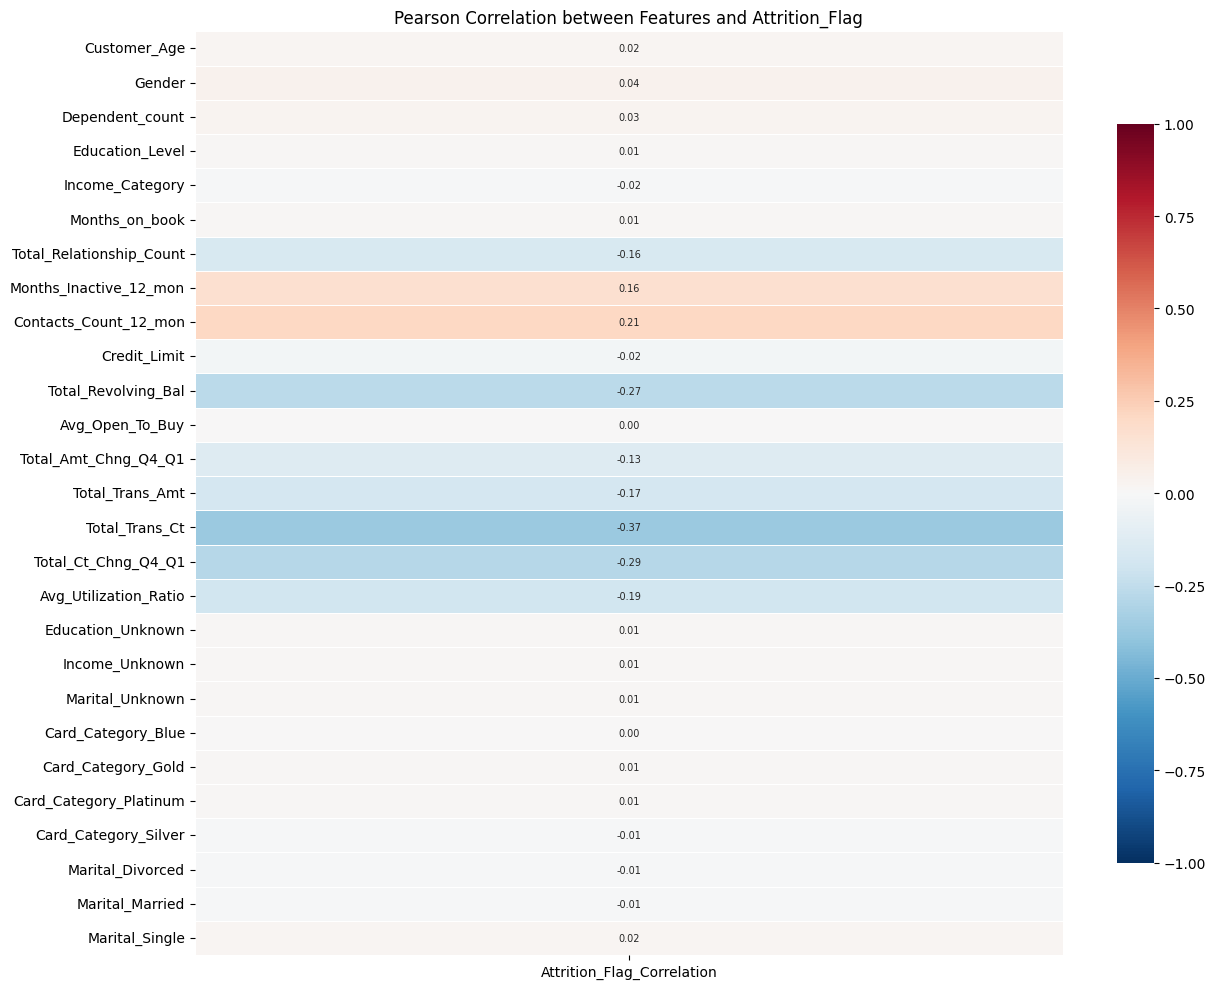

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

corr_series = X_train.corrwith(y_train, method='pearson')

corr_df = corr_series.to_frame(name='Attrition_Flag_Correlation')

plt.figure(figsize=(13, 10))

sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=.5,
            annot_kws={'size': 7}, cbar_kws={'shrink': .8})
plt.title('Pearson Correlation between Features and Attrition_Flag')
plt.tight_layout()
plt.show()

In [ ]:
compare = filter_df.merge(wrapper_df, on='feature')
print(compare)

                     feature        score         pvalue  mutual_info  \
0             Total_Trans_Ct  1304.840615  4.672547e-265     0.117308   
1        Total_Ct_Chng_Q4_Q1   724.081801  7.826216e-153     0.097107   
2        Total_Revolving_Bal   624.638229  7.200815e-133     0.086718   
3      Contacts_Count_12_mon   357.053749   5.766715e-78     0.031237   
4      Avg_Utilization_Ratio   298.439252   1.074262e-65     0.056820   
5            Total_Trans_Amt   251.300721   9.267982e-56     0.158251   
6     Months_Inactive_12_mon   207.190324   2.099911e-46     0.020610   
7   Total_Relationship_Count   204.922922   6.377533e-46     0.012831   
8       Total_Amt_Chng_Q4_Q1   137.395987   1.772444e-31     0.031095   
9            Dependent_count     7.760686   5.351984e-03     0.002122   
10              Credit_Limit     4.658394   3.093137e-02     0.000305   
11              Customer_Age     2.412416   1.204155e-01     0.000000   
12            Months_on_book     0.534546   4.64723

In [ ]:
compare = filter_df.merge(wrapper_df, on='feature')

# Vote 1: Statistically significant (p < 0.05) — เทียบข้าม ANOVA/Chi-square ได้ตรงเพราะ pvalue สเกลเดียวกัน
compare['vote_significant'] = (compare['pvalue'] < 0.05).astype(int)

# Vote 2: ติด top 10 ของ mutual_info — universal metric เทียบข้าม type ได้จริง
compare['rank_mi'] = compare['mutual_info'].rank(ascending=False)
compare['vote_mi'] = (compare['rank_mi'] <= 10).astype(int)

# Vote 3: RFE เลือก (Wrapper)
compare['vote_rfe'] = compare['rfe_selected'].astype(int)

# รวมคะแนนโหวต
compare['votes'] = compare['vote_significant'] + compare['vote_mi'] + compare['vote_rfe']

final_ranking = compare[[
    'feature', 'pvalue', 'mutual_info', 'rfe_selected',
    'vote_significant', 'vote_mi', 'vote_rfe', 'votes'
]].sort_values('votes', ascending=False)

print(final_ranking)

# เลือก feature ที่ agree อย่างน้อย 2 ใน 3 โหวต
selected_features = final_ranking[final_ranking['votes'] >= 3]['feature'].tolist()
print(f"\nFeatures selected (agree by >=3/3 votes): {len(selected_features)} features")
print(selected_features)

                     feature         pvalue  mutual_info  rfe_selected  \
0             Total_Trans_Ct  4.672547e-265     0.117308          True   
1        Total_Ct_Chng_Q4_Q1  7.826216e-153     0.097107          True   
2        Total_Revolving_Bal  7.200815e-133     0.086718          True   
3      Contacts_Count_12_mon   5.766715e-78     0.031237          True   
5            Total_Trans_Amt   9.267982e-56     0.158251          True   
6     Months_Inactive_12_mon   2.099911e-46     0.020610          True   
7   Total_Relationship_Count   6.377533e-46     0.012831          True   
4      Avg_Utilization_Ratio   1.074262e-65     0.056820         False   
8       Total_Amt_Chng_Q4_Q1   1.772444e-31     0.031095         False   
9            Dependent_count   5.351984e-03     0.002122          True   
14                    Gender   9.337271e-03     0.000886          True   
10              Credit_Limit   3.093137e-02     0.000305         False   
13           Avg_Open_To_Buy   9.88411

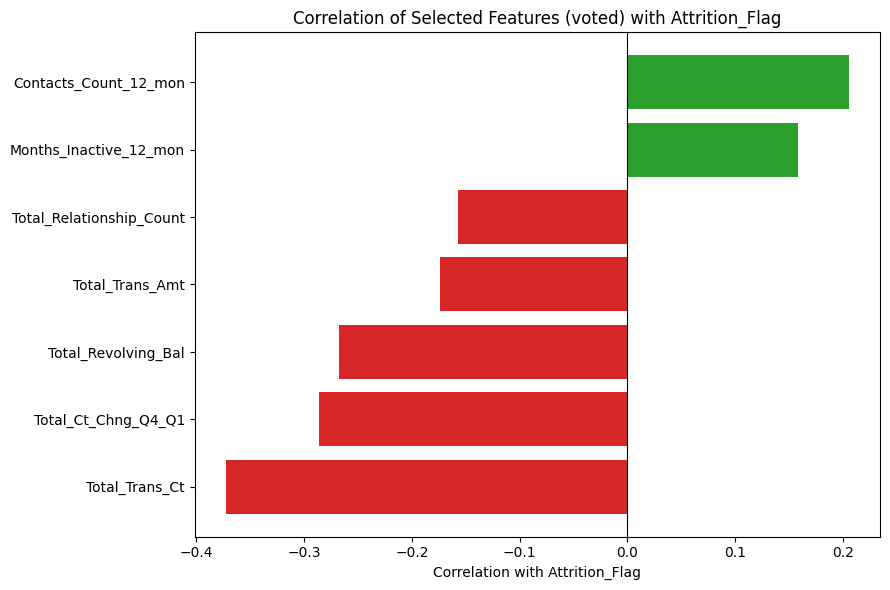

In [ ]:
import matplotlib.pyplot as plt

corr_selected = X_train[selected_features].corrwith(y_train).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
colors = ['#d62728' if v < 0 else '#2ca02c' for v in corr_selected.values]
plt.barh(corr_selected.index, corr_selected.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation with Attrition_Flag')
plt.title('Correlation of Selected Features (voted) with Attrition_Flag')
plt.gca().invert_yaxis()  # ให้ตัวที่ correlation แรงสุดอยู่บนสุด
plt.tight_layout()
plt.show()

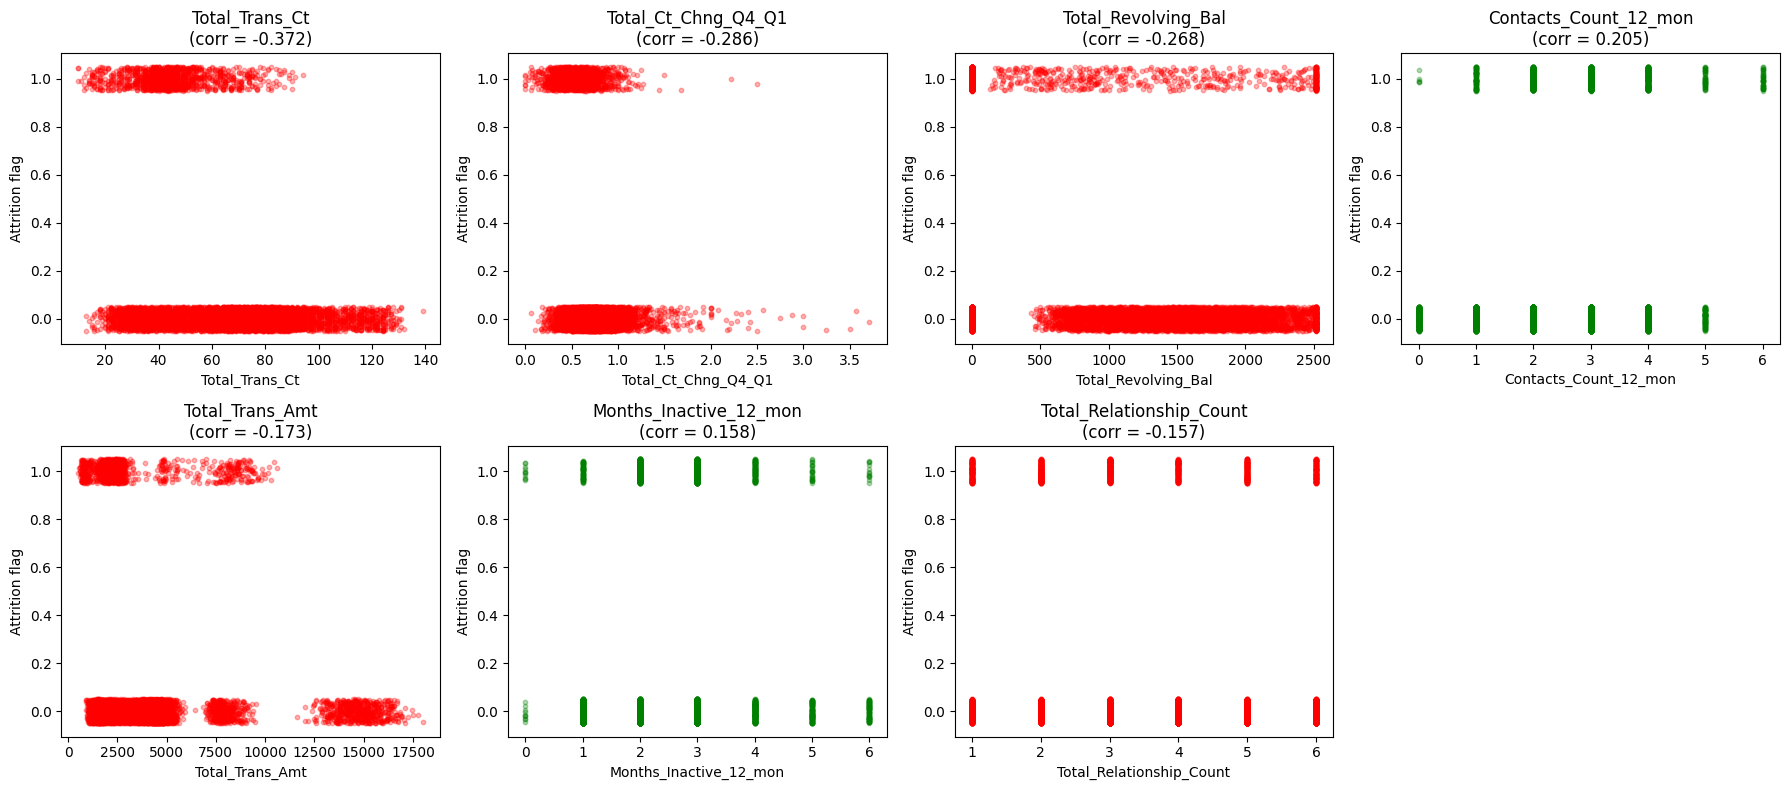

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

n_features = len(selected_features)
n_cols = 4
n_rows = -(-n_features // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

# jitter ค่า y (0/1) เล็กน้อย เพราะ target เป็น binary ไม่งั้นจุดจะซ้อนทับกันเป็นเส้นตรง 2 เส้น
y_jitter = y_train + np.random.uniform(-0.05, 0.05, size=len(y_train))

for i, feat in enumerate(selected_features):
    corr_val = corr_selected[feat]
    color = 'green' if corr_val > 0 else 'red'
    axes[i].scatter(X_train[feat], y_jitter, alpha=0.3, s=10, color=color)
    axes[i].set_title(f"{feat}\n(corr = {corr_val:.3f})")
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Attrition flag')

for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Regression

In [ ]:
reg_base = data.copy()
reg_base

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Education_Unknown,Income_Unknown,Marital_Unknown,Card_Category_Blue,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Marital_Divorced,Marital_Married,Marital_Single
0,0,45,0,3,1.0,2.0,39,5,1,3,...,0,0,0,True,False,False,False,False,True,False
1,0,49,1,5,3.0,0.0,44,6,1,2,...,0,0,0,True,False,False,False,False,False,True
2,0,51,0,3,3.0,3.0,36,4,1,0,...,0,0,0,True,False,False,False,False,True,False
3,0,40,1,4,1.0,0.0,34,3,4,1,...,0,0,1,True,False,False,False,False,True,False
4,0,40,0,3,0.0,2.0,21,5,1,0,...,0,0,0,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,0,50,0,2,3.0,1.0,40,3,2,3,...,0,0,0,True,False,False,False,False,False,True
10123,1,41,0,2,2.0,1.0,25,4,2,3,...,1,0,0,True,False,False,False,True,False,False
10124,1,44,1,1,1.0,0.0,36,5,3,4,...,0,0,0,True,False,False,False,False,True,False
10125,1,30,0,2,3.0,1.0,36,4,3,3,...,0,0,1,True,False,False,False,False,True,False


In [ ]:
Data_leak = ['Avg_Open_To_Buy', 'Avg_Utilization_Ratio']

y_reg = reg_base['Credit_Limit']
X_reg = reg_base.drop(columns=['Credit_Limit'] + Data_leak).astype(float)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

print('ฟีเจอร์:', X_reg.shape[1])
print('Train:', Xr_train.shape[0], '| Test:', Xr_test.shape[0])
print()
print(X_reg.corrwith(y_reg).abs().sort_values(ascending=False).head(10).round(3).to_string())

ฟีเจอร์: 25
Train: 8101 | Test: 2026

Income_Category             0.563
Card_Category_Blue          0.516
Card_Category_Silver        0.441
Gender                      0.421
Card_Category_Gold          0.234
Total_Trans_Amt             0.172
Card_Category_Platinum      0.106
Total_Trans_Ct              0.076
Total_Relationship_Count    0.071
Dependent_count             0.068


In [ ]:
# Filter

from sklearn.feature_selection import f_regression, mutual_info_regression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer

cat_candidates = ['Gender', 'Education_Level', 'Card_Category_Blue','Card_Category_Silver','Card_Category_Gold','Card_Category_Platinum',
                         'Income_Category', 'Marital_Divorced', 'Marital_Single', 'Marital_Married',
                         'Education_Unknown', 'Income_Unknown','Marital_Unknown']

r_cat = [c for c in cat_candidates if c in X_reg.columns]
r_num = [c for c in X_reg.columns if c not in r_cat]

f_num, p_num = f_regression(Xr_train[r_num], yr_train)
mi_num = mutual_info_regression(Xr_train[r_num], yr_train, random_state=42)

Xr_train_categorical_reg = Xr_train[r_cat] # Capture the actual columns being used
f_cat, p_cat = f_regression(Xr_train_categorical_reg, yr_train)
mi_cat = mutual_info_regression(Xr_train_categorical_reg, yr_train,
                                discrete_features=True, random_state=42)

r_filter = pd.concat([
    pd.DataFrame({'feature': r_num, 'score': f_num, 'pvalue': p_num, 'mutual_info': mi_num}),
    pd.DataFrame({'feature': Xr_train_categorical_reg.columns.tolist(), 'score': f_cat, 'pvalue': p_cat, 'mutual_info': mi_cat})
], ignore_index=True)

print(r_filter.sort_values('score', ascending=False).to_string(index=False))

r_scaler = StandardScaler()
Xr_scaled = r_scaler.fit_transform(Xr_train)
Xr_test_scaled = r_scaler.transform(Xr_test)


                 feature       score        pvalue  mutual_info
         Income_Category 3818.741260  0.000000e+00     0.211580
      Card_Category_Blue 2860.832605  0.000000e+00     0.116305
    Card_Category_Silver 1863.773769  0.000000e+00     0.084387
                  Gender 1793.463987  0.000000e+00     0.130455
      Card_Category_Gold  519.128770 1.972602e-111     0.030937
         Total_Trans_Amt  242.378319  7.156694e-54     0.106803
  Card_Category_Platinum   75.218274  5.036403e-18     0.006265
          Total_Trans_Ct   46.951240  7.810232e-12     0.039888
Total_Relationship_Count   42.747424  6.605692e-11     0.015129
         Dependent_count   40.271042  2.329421e-10     0.013437
     Total_Revolving_Bal   22.299996  2.371283e-06     0.125726
         Marital_Married   10.687931  1.082868e-03     0.000000
         Marital_Unknown    9.354084  2.232156e-03     0.004984
   Contacts_Count_12_mon    6.392163  1.148137e-02     0.000000
          Marital_Single    6.081002  1.

In [ ]:
# wrapper

from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE

rfe_reg = RFE(estimator=LinearRegression(), n_features_to_select=10)
rfe_reg.fit(Xr_scaled, yr_train)

r_wrapper = pd.DataFrame({
    'feature': X_reg.columns,
    'rfe_selected': rfe_reg.support_,
    'rfe_rank': rfe_reg.ranking_
}).sort_values('rfe_rank')

print(r_wrapper.head(15).to_string(index=False))

               feature  rfe_selected  rfe_rank
       Dependent_count          True         1
       Income_Category          True         1
       Total_Trans_Amt          True         1
        Total_Trans_Ct          True         1
Card_Category_Platinum          True         1
    Card_Category_Gold          True         1
    Card_Category_Blue          True         1
        Income_Unknown          True         1
  Card_Category_Silver          True         1
       Marital_Married          True         1
       Marital_Unknown         False         2
        Attrition_Flag         False         3
 Contacts_Count_12_mon         False         4
      Marital_Divorced         False         5
        Marital_Single         False         6


In [ ]:
# compare

r_compare = r_filter.merge(r_wrapper, on='feature')

r_compare['vote_sig'] = (r_compare['pvalue'] < 0.05).astype(int)
r_compare['vote_mi'] = (r_compare['mutual_info'].rank(ascending=False) <= 10).astype(int)
r_compare['vote_rfe'] = r_compare['rfe_selected'].astype(int)
r_compare['votes'] = r_compare['vote_sig'] + r_compare['vote_mi'] + r_compare['vote_rfe']

r_ranking = r_compare[['feature', 'pvalue', 'mutual_info', 'rfe_selected', 'votes']] \
    .sort_values('votes', ascending=False)
print(r_ranking.to_string(index=False))

r_selected = r_ranking[r_ranking['votes'] >= 3]['feature'].tolist()
print(f'\nเลือกได้ {len(r_selected)} ฟีเจอร์:')
print(r_selected)

                 feature        pvalue  mutual_info  rfe_selected  votes
         Dependent_count  2.329421e-10     0.013437          True      3
      Card_Category_Blue  0.000000e+00     0.116305          True      3
    Card_Category_Silver  0.000000e+00     0.084387          True      3
         Income_Category  0.000000e+00     0.211580          True      3
      Card_Category_Gold 1.972602e-111     0.030937          True      3
          Total_Trans_Ct  7.810232e-12     0.039888          True      3
         Total_Trans_Amt  7.156694e-54     0.106803          True      3
     Total_Revolving_Bal  2.371283e-06     0.125726         False      2
Total_Relationship_Count  6.605692e-11     0.015129         False      2
          Income_Unknown  2.509107e-02     0.008089          True      2
         Marital_Married  1.082868e-03     0.000000          True      2
  Card_Category_Platinum  5.036403e-18     0.006265          True      2
                  Gender  0.000000e+00     0.130455

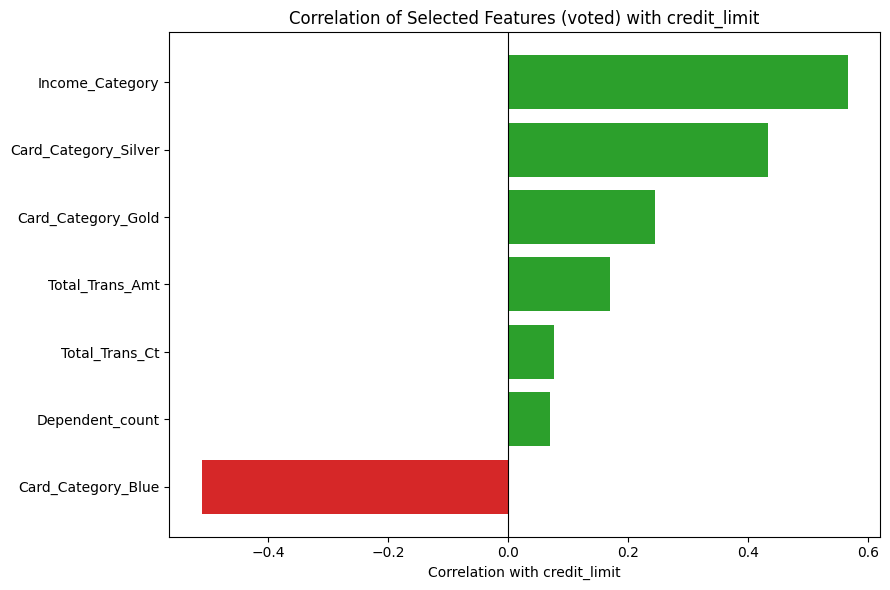

In [ ]:
import matplotlib.pyplot as plt

corr_selected = Xr_train[r_selected].corrwith(yr_train).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
colors = ['#d62728' if v < 0 else '#2ca02c' for v in corr_selected.values]
plt.barh(corr_selected.index, corr_selected.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation with credit_limit')
plt.title('Correlation of Selected Features (voted) with credit_limit')
plt.gca().invert_yaxis()  # ให้ตัวที่ correlation แรงสุดอยู่บนสุด
plt.tight_layout()
plt.show()

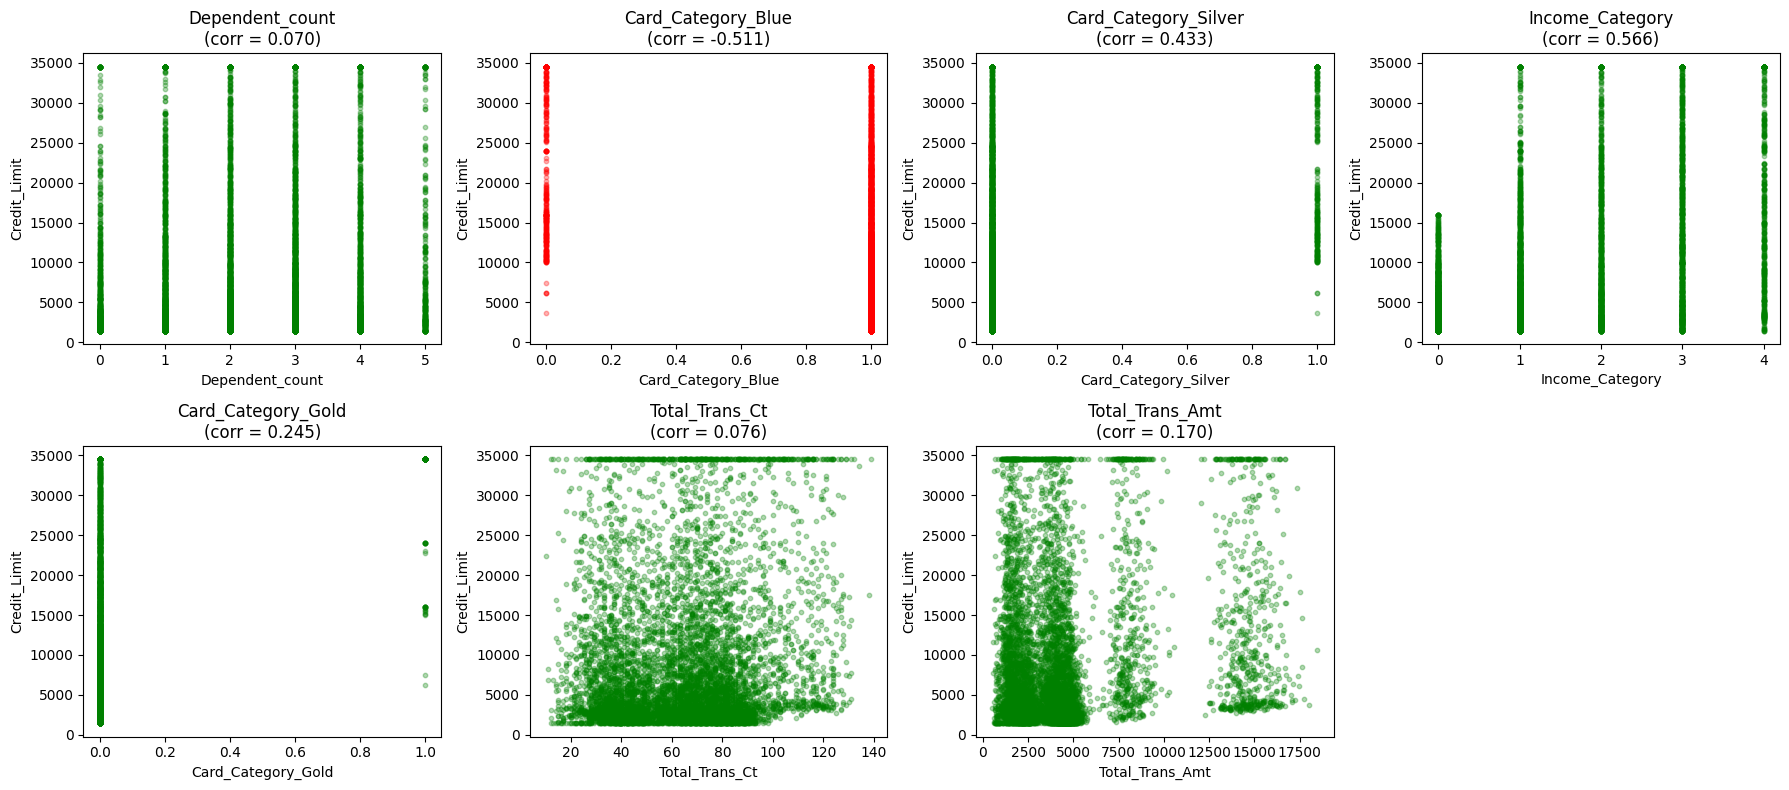

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n_features = len(r_selected)
n_cols = 4
n_rows = -(-n_features // n_cols)

# คำนวณ correlation กับ Credit_Limit ใหม่ (ไม่ใช่ค่าเก่าจาก Attrition_Flag)
corr_credit = Xr_train[r_selected].corrwith(yr_train)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, feat in enumerate(r_selected):
    corr_val = corr_credit[feat]
    color = 'green' if corr_val > 0 else 'red'
    axes[i].scatter(Xr_train[feat], yr_train, alpha=0.3, s=10, color=color)  # ไม่ jitter
    axes[i].set_title(f"{feat}\n(corr = {corr_val:.3f})")
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Credit_Limit')

for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

# ใช้ selected features ที่ได้จาก voting (r_selected)
model_quick = LinearRegression()

cv = KFold(n_splits=5, shuffle=True, random_state=42)
r2_scores = cross_val_score(model_quick, Xr_train[r_selected], yr_train, cv=cv, scoring='r2')

print("R² each fold:", r2_scores)
print(f"Mean R²: {r2_scores.mean():.4f} (+/- {r2_scores.std():.4f})")

R² each fold: [0.5178384  0.55896333 0.51699789 0.55879163 0.56659464]
Mean R²: 0.5438 (+/- 0.0218)


In [46]:
# ยืนยันบน test set: fit บน train อย่างเดียว แล้ววัด R² บน test ที่ไม่เคยใช้ตัดสินใจ
def r2_score_np(y, p):
    y = np.asarray(y, dtype=float)
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def design(D, levels, tier_val=None, mode="dummy"):
    inc = D['Income_Category'].values
    inc_oh = np.column_stack([(inc == v).astype(float) for v in levels[1:]])
    other = D[['Income_Unknown', 'Total_Trans_Amt']].values
    if mode == "dummy":
        card = D[['Card_Category_Blue', 'Card_Category_Silver', 'Card_Category_Gold']].values
    elif mode == "ord":
        card = (D['Card_Category_Silver'] + 2 * D['Card_Category_Gold'] + 3 * D['Card_Category_Platinum']).values[:, None]
    else:  # ลำดับตามค่าเฉลี่ยวงเงิน ใช้ค่าที่คำนวณจาก train เท่านั้น
        k = np.select([D['Card_Category_Blue'] == 1, D['Card_Category_Silver'] == 1, D['Card_Category_Gold'] == 1], [0, 1, 2], default=3)
        card = tier_val[k][:, None]
    return np.c_[inc_oh, card, other, np.hstack([inc_oh * card[:, [j]] for j in range(card.shape[1])])]

levels = np.unique(Xr_train['Income_Category'].values)
k_tr = np.select([Xr_train['Card_Category_Blue'] == 1, Xr_train['Card_Category_Silver'] == 1, Xr_train['Card_Category_Gold'] == 1], [0, 1, 2], default=3)
tier_val = np.array([yr_train.values[k_tr == k].mean() for k in range(4)])

def fit_eval(Mtr, Mte):
    mu, sd = Mtr.mean(axis=0), Mtr.std(axis=0); sd[sd == 0] = 1.0     # scale ด้วยสถิติของ train
    A = np.c_[np.ones(len(Mtr)), (Mtr - mu) / sd]
    theta = np.linalg.lstsq(A, yr_train.values, rcond=None)[0]
    pred = np.c_[np.ones(len(Mte)), (Mte - mu) / sd] @ theta
    return round(r2_score_np(yr_test, pred), 4)

res = {
    "7 feature เดิม": fit_eval(Xr_train[r_selected].values, Xr_test[r_selected].values),
    "dummy": fit_eval(design(Xr_train, levels), design(Xr_test, levels)),
    "ลำดับ 0 ถึง 3": fit_eval(design(Xr_train, levels, mode="ord"), design(Xr_test, levels, mode="ord")),
    "ลำดับตามค่าเฉลี่ยวงเงิน": fit_eval(design(Xr_train, levels, tier_val, "mean"), design(Xr_test, levels, tier_val, "mean")),
}
pd.Series(res, name="test R²").to_frame()

,test R²
7 feature เดิม,0.5385
dummy,0.5758
ลำดับ 0 ถึง 3,0.5450
ลำดับตามค่าเฉลี่ยวงเงิน,0.5742


# data insight

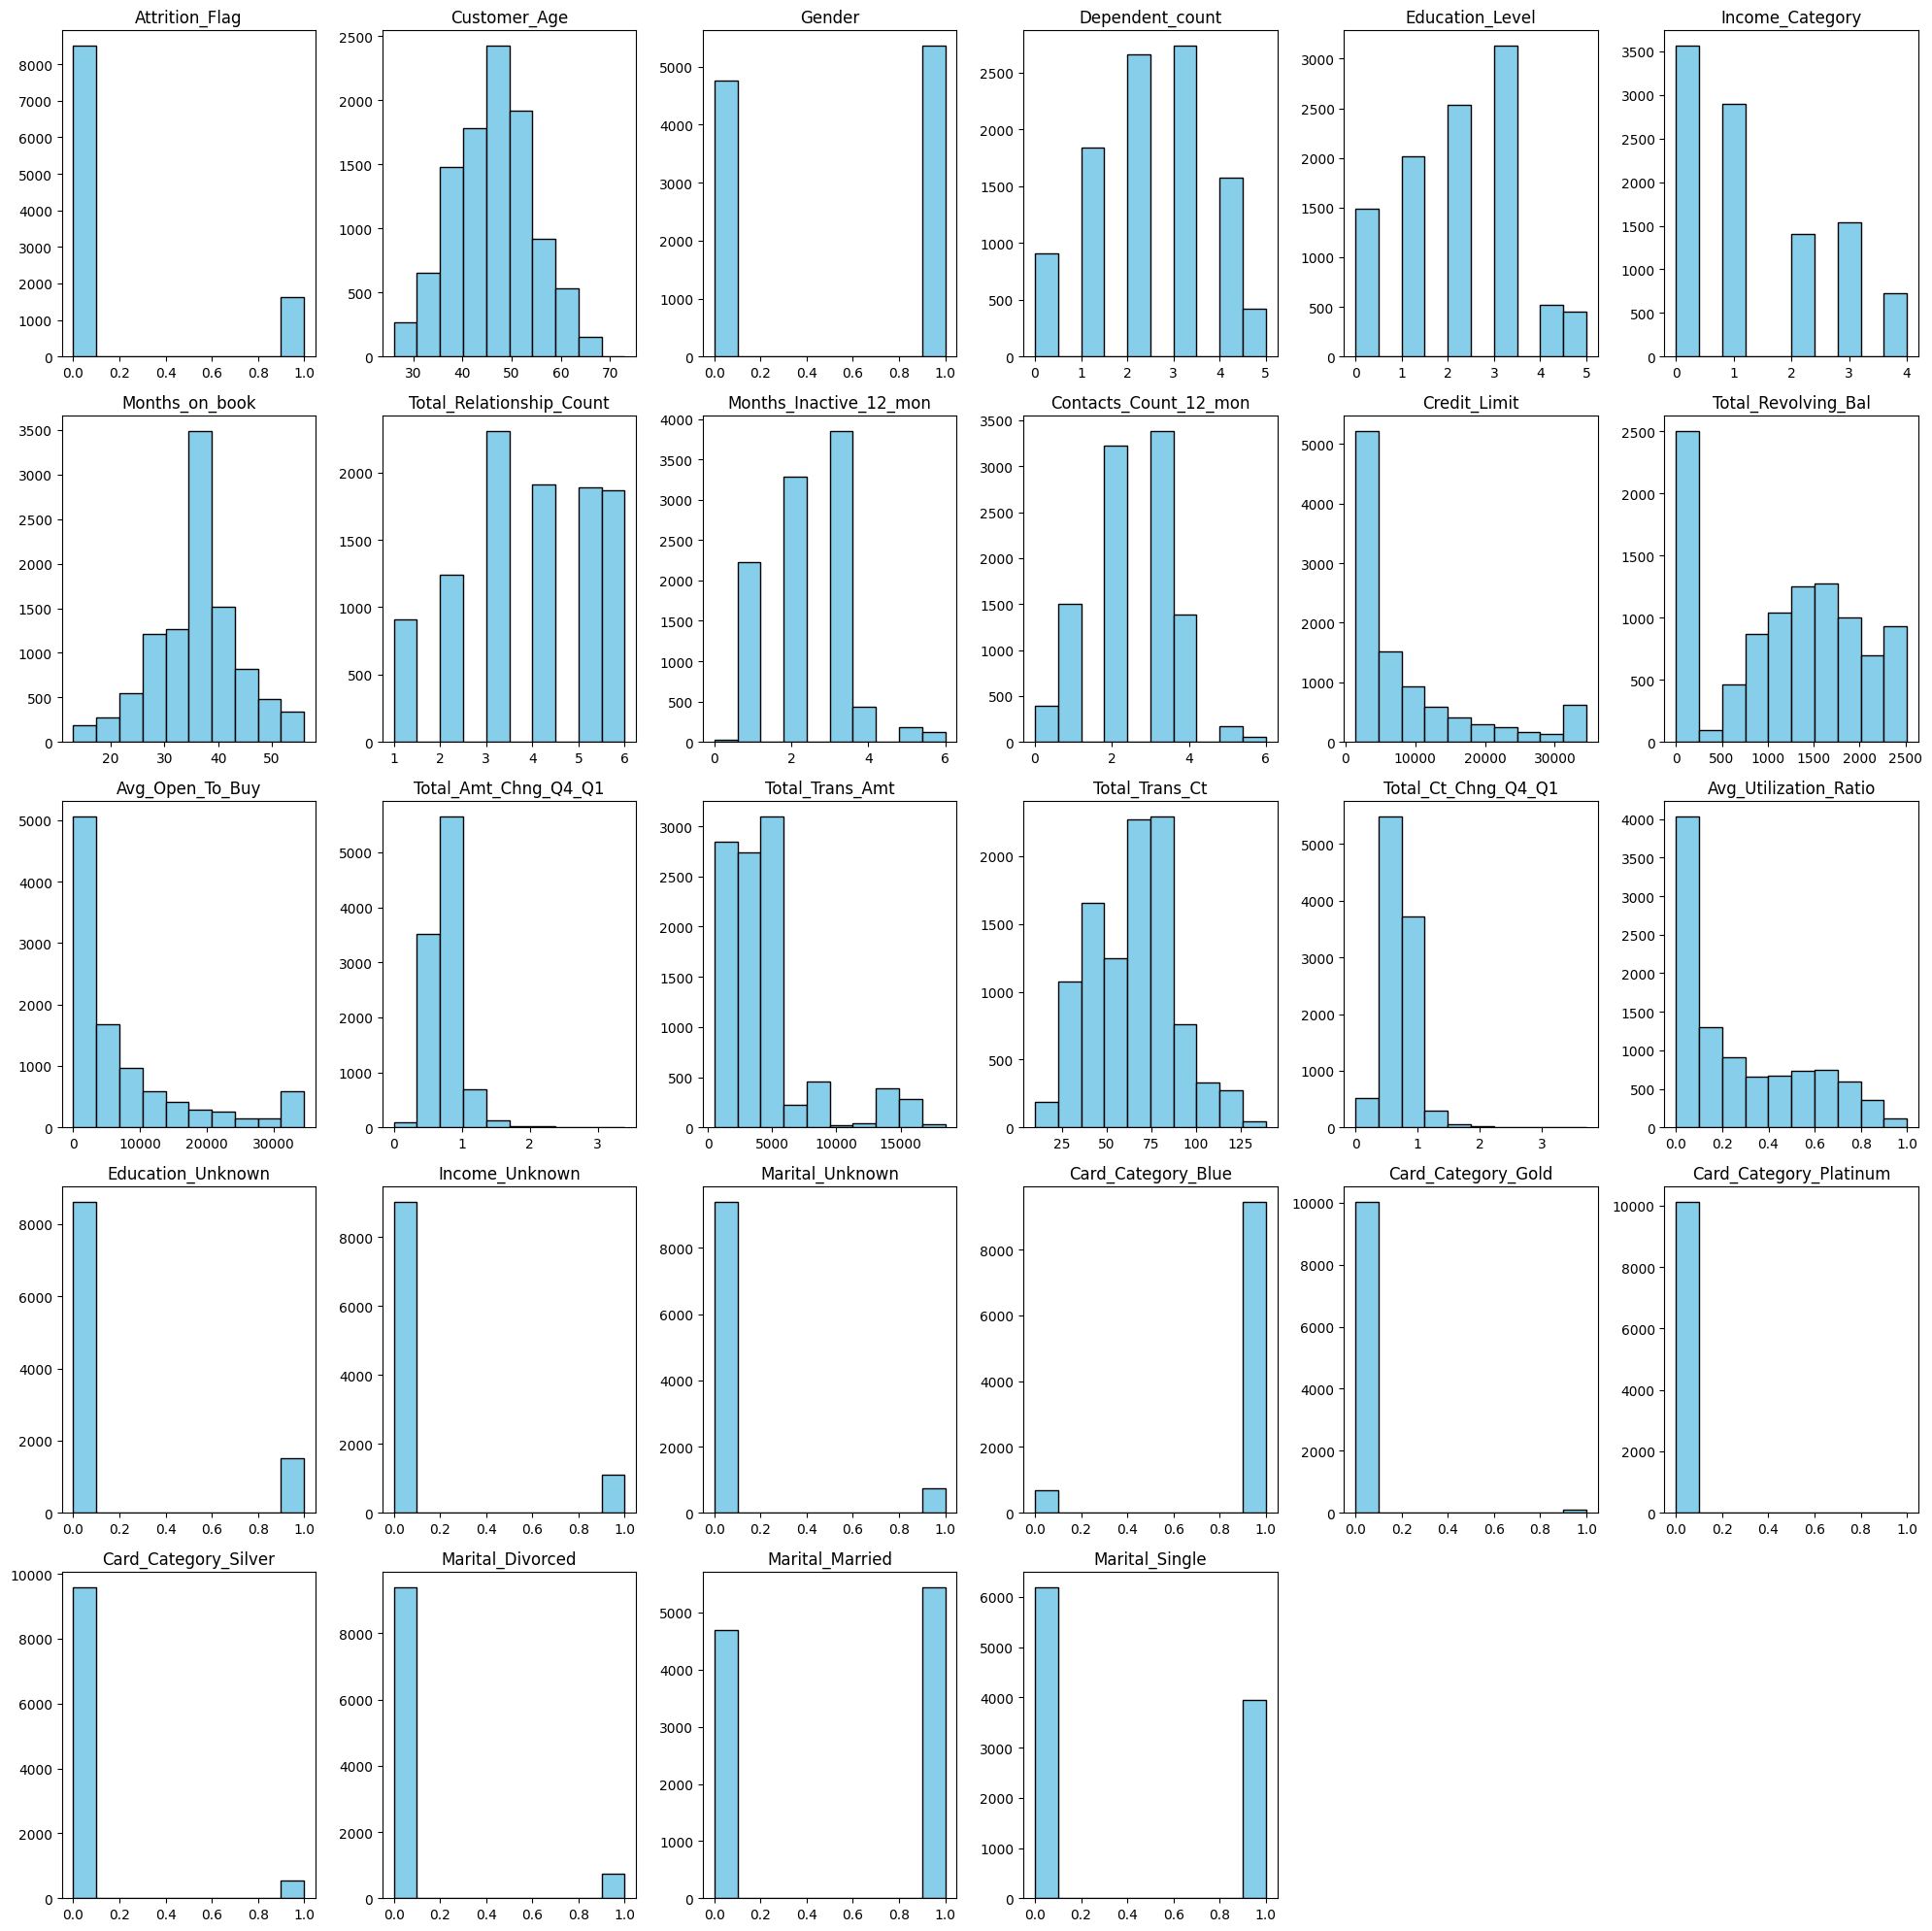

In [ ]:
plt.figure(figsize=(20, 20))

for i, col in enumerate(data.columns):
    plt.subplot(5, 6, i + 1)
    # Convert boolean columns to integers before plotting histograms
    if pd.api.types.is_bool_dtype(data[col]):
        plt.hist(data[col].astype(int), color='skyblue', edgecolor='black')
    else:
        plt.hist(data[col], color='skyblue', edgecolor='black')
    plt.title(col)
    plt.tight_layout()

plt.show()

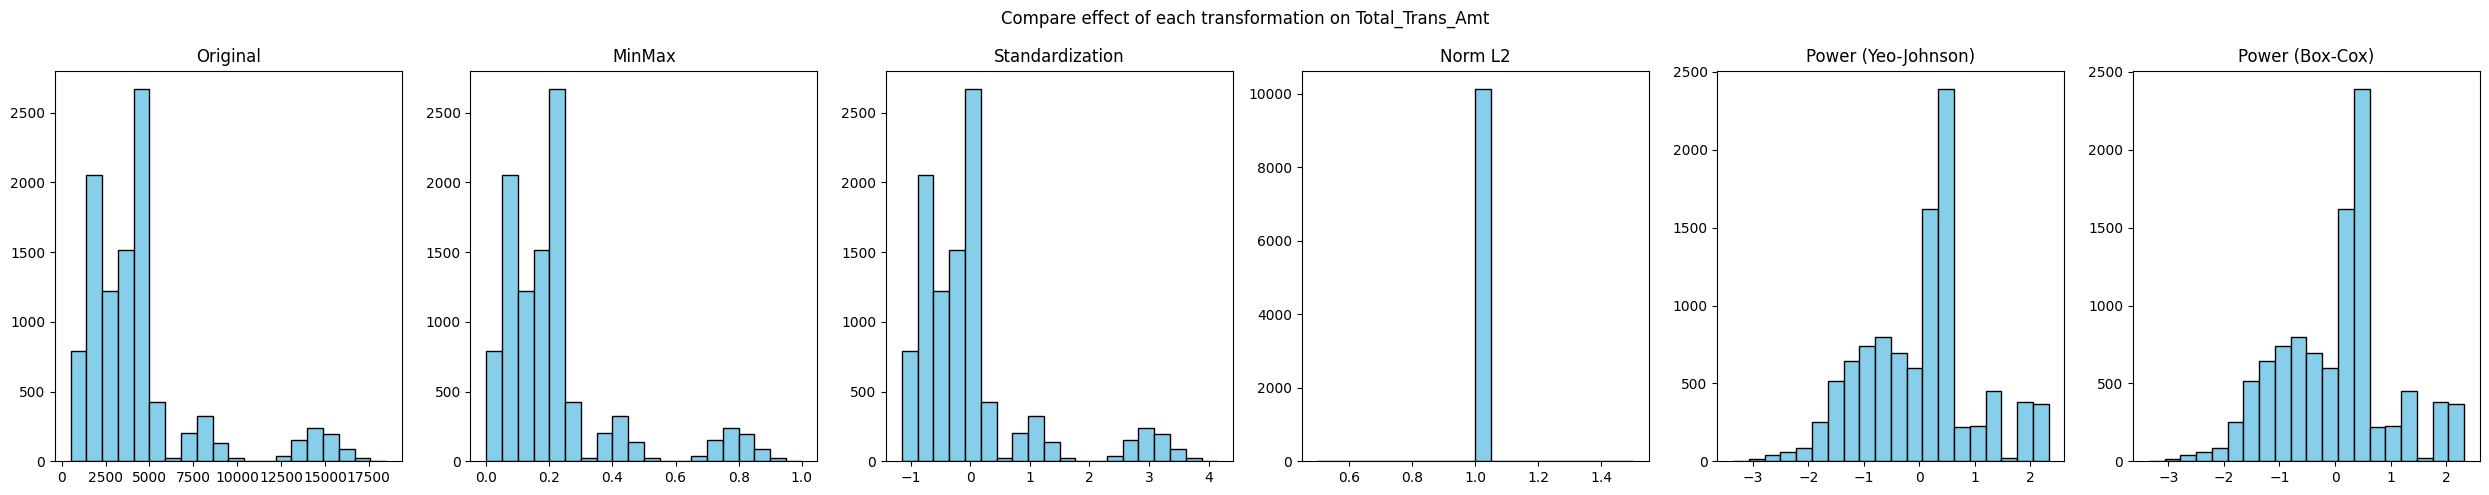

In [ ]:
#plot histrogram ของการ standardize แต่ละแบบ
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
    Normalizer,
    OneHotEncoder,
    LabelEncoder,
    PowerTransformer,
    KBinsDiscretizer
)

from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer, PowerTransformer

feature_to_check = 'Total_Trans_Amt'  # เปลี่ยนเป็น feature ที่อยากดูได้

scaler_minmax = MinMaxScaler()
scaler_standard = StandardScaler()
scaler_norm = Normalizer()
scaler_yeo = PowerTransformer(method='yeo-johnson')
scaler_box = PowerTransformer(method='box-cox')

data_minmax = scaler_minmax.fit_transform(data[[feature_to_check]])
data_standard = scaler_standard.fit_transform(data[[feature_to_check]])
data_norm = scaler_norm.fit_transform(data[[feature_to_check]])
data_yeo = scaler_yeo.fit_transform(data[[feature_to_check]])
data_box = scaler_box.fit_transform(data[[feature_to_check]])  # ต้องการค่า > 0 ทั้งหมด

fig, ax = plt.subplots(nrows=1, ncols=6, figsize=(25, 5))
fig.suptitle(f"Compare effect of each transformation on {feature_to_check}")

ax[0].hist(data[feature_to_check], color='skyblue', edgecolor='black', bins=20)
ax[0].set_title("Original")

ax[1].hist(data_minmax[:, 0], color='skyblue', edgecolor='black', bins=20)
ax[1].set_title("MinMax")

ax[2].hist(data_standard[:, 0], color='skyblue', edgecolor='black', bins=20)
ax[2].set_title("Standardization")

ax[3].hist(data_norm[:, 0], color='skyblue', edgecolor='black', bins=20)
ax[3].set_title("Norm L2")

ax[4].hist(data_yeo[:, 0], color='skyblue', edgecolor='black', bins=20)
ax[4].set_title("Power (Yeo-Johnson)")

ax[5].hist(data_box[:, 0], color='skyblue', edgecolor='black', bins=20)
ax[5].set_title("Power (Box-Cox)")

plt.tight_layout()
plt.show()

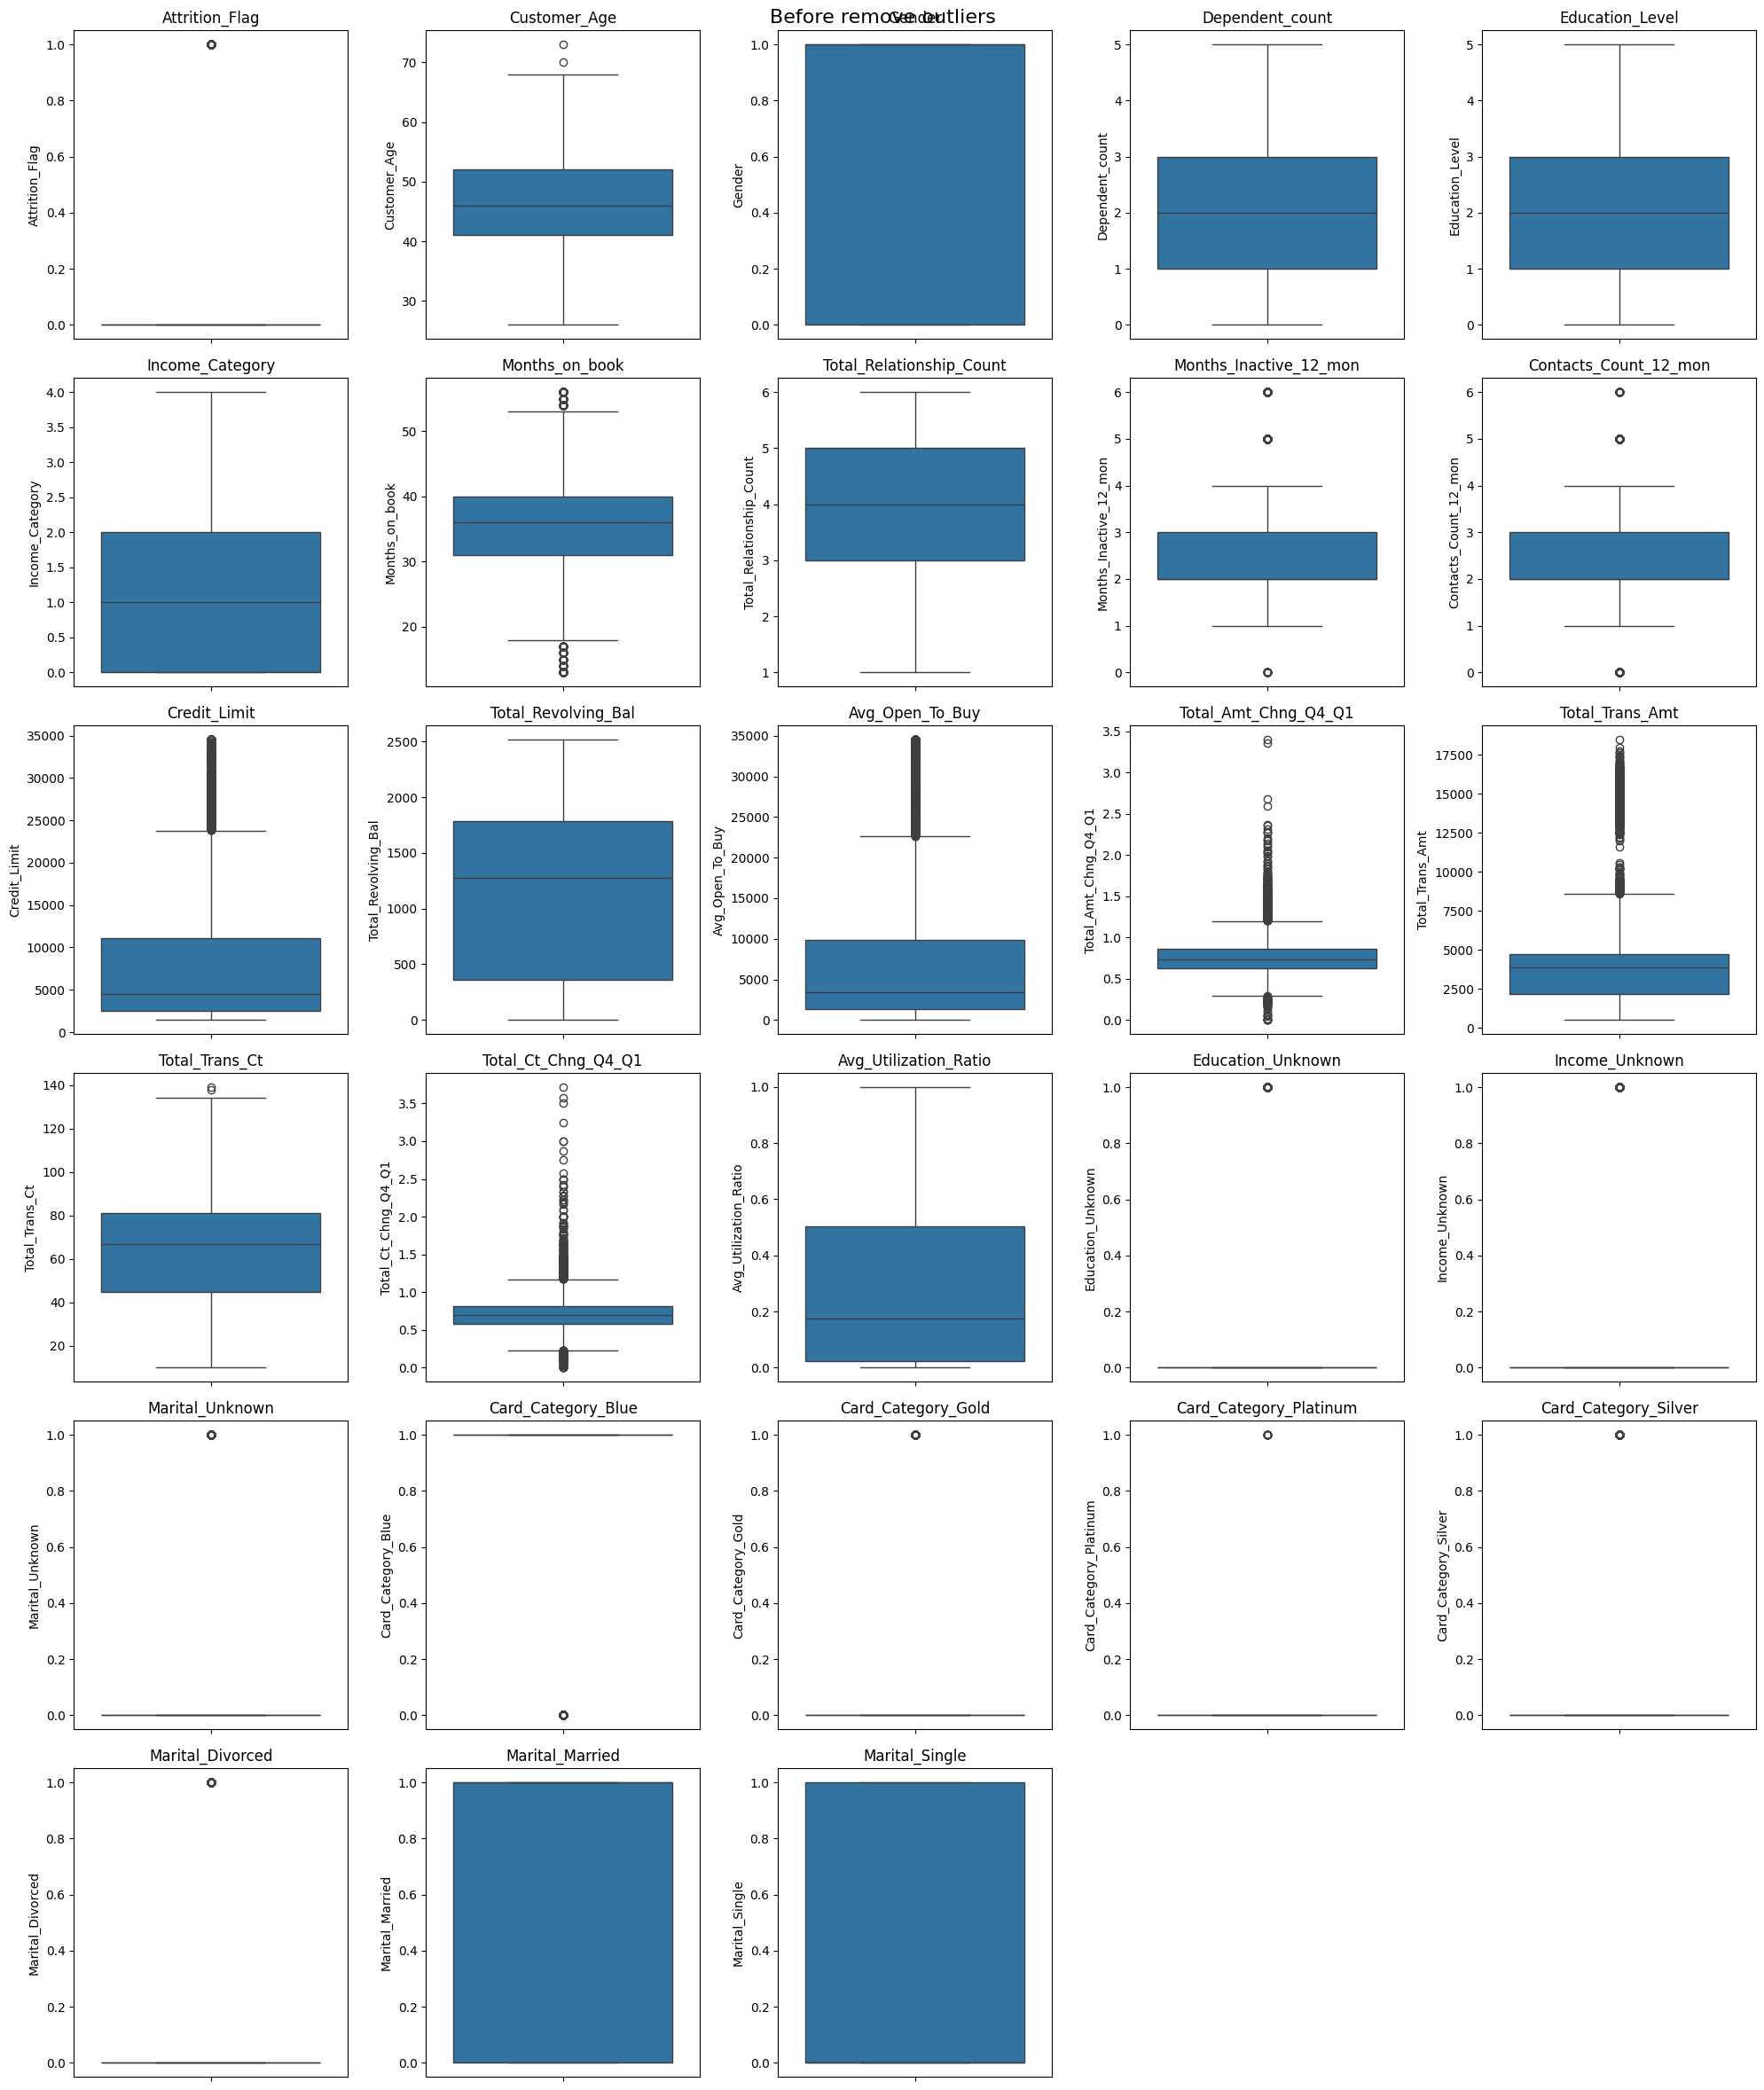

In [ ]:
n_cols = len(data.columns)
n_grid_cols = 5
n_grid_rows = -(-n_cols // n_grid_cols)  # ปัดขึ้น

fig, axes = plt.subplots(nrows=n_grid_rows, ncols=n_grid_cols, figsize=(20, 4 * n_grid_rows))
axes = axes.flatten()

fig.suptitle("Before remove outliers", fontsize=16)

for i, col in enumerate(data.columns):
    if pd.api.types.is_bool_dtype(data[col]):
        sns.boxplot(y=data[col].astype(int), ax=axes[i])
    else:
        sns.boxplot(y=data[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(n_cols, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()